In [2]:
from google.colab import drive
import os

# Montar Google Drive
drive.mount('/content/drive')

# ¡Cambia esta ruta por la carpeta exacta donde tengas tus archivos en tu Drive!
# Ejemplo: os.chdir('/content/drive/MyDrive/Proyecto_Armonix')
# O si creaste una carpeta 'data/raw', asegúrate de apuntar ahí.

os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('figs', exist_ok=True)

print("Entorno listo y directorios creados.")

Mounted at /content/drive
Entorno listo y directorios creados.


In [3]:
import pandas as pd
import glob

# Verificamos los archivos CSV disponibles en el directorio actual o en data/raw
print("--- Verificando archivos CSV disponibles ---")
archivos_csv = glob.glob('*.csv') + glob.glob('data/raw/*.csv')
for arch in archivos_csv:
    print(f"Encontrado: {arch}")

# Ejemplo de lectura rápida del archivo de matrícula 2023 para validar columnas y separador (usualmente separador ';' en Mineduc)
# df_mat_2023 = pd.read_csv('20230906_Matrícula_unica_2023_20230430_R.csv', sep=';', low_memory=False)
# print("Dimensiones Matrícula 2023:", df_mat_2023.shape)

--- Verificando archivos CSV disponibles ---
Encontrado: 20250212_Rendimiento_2024_20250131_WEB.csv
Encontrado: 20260210_Rendimiento_2025_20260202_WEB.csv
Encontrado: 20240209_Rendimiento_2023_20240131_WEB.csv


In [6]:
!pip install -q pypdf

In [7]:
import sys
import subprocess

# Instalación forzada en el entorno activo actual
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pypdf"])

import pypdf

def leer_pautas_pdf(ruta_archivo):
    print(f"=== LEYENDO ARCHIVO: {ruta_archivo} ===\n")
    try:
        reader = pypdf.PdfReader(ruta_archivo)
        for num_pag, pagina in enumerate(reader.pages):
            texto = pagina.extract_text()
            print(f"--- Página {num_pag + 1} ---")
            print(texto[:2000]) # Mostramos hasta 2000 caracteres por página
            print("\n" + "="*50 + "\n")
    except Exception as e:
        print(f"Error al leer {ruta_archivo}: {e}")

# Analizar ambos archivos de pauta
leer_pautas_pdf('/content/informe3-4-pauta.pdf')
print("\n" + "*"*60 + "\n")
leer_pautas_pdf('/content/Informe Acumulativo 3 y 4-Taller de Ciencia de DatosBE.pdf')

=== LEYENDO ARCHIVO: /content/informe3-4-pauta.pdf ===

--- Página 1 ---
Taller de Ciencia de Datos Informes 3 y 4 — Pauta
Taller de Ciencia de Datos (EIN146A25)
Informes 3 y 4: Exploraci´ on, caracter ´ ısticas relevantes, modelado y evaluaci´ on
Profesor: Diego Ram ´ ırez Semestre: 2026-2 · Paralelo 701
Entrega: Domingo 8 de noviembre, 23:59 hrs V ´ ıa:AULA-USM
Qu´ e eval´ ua esta entrega
La pauta del Informe 3 no se public´ o en la fecha prevista (08-oct) y su plazo se superpone
con el del Informe 4 (22-oct). Por eso los dos informes se entregan juntos, en un solo documento
acumulativo y continuo (ver la estructura en la Secci´ on 1) y un solo repositorio. Se registran
dos notas , cada una sobre 100 puntos y con el 12 % que fija el programa: las secciones 5 del
documento se califican como Informe 3 y las secciones 6 como Informe 4.
Informe 3 (Secci´ on 5): exploraci´ on y caracter ´ ısticas relevantes.Parte del dataset limpio
del Informe 2 y termina en unaficha de variables candidat

In [5]:
import pandas as pd

# Dado que el dataset ya fue consolidado y exportado de forma segura en la celda anterior,
# cargamos una pequeña muestra para inspeccionar el resultado final sin saturar la RAM.

ruta_parquet = '/content/data/processed/dataset_final.parquet'
if pd.io.common.file_exists(ruta_parquet):
    df_muestra = pd.read_parquet(ruta_parquet)
    print("--- RESUMEN DEL DATASET PROCESADO (dataset_final.parquet) ---")
    print(f"Cantidad total de registros: {len(df_muestra):,}")
    print("\nPrimeros registros del dataset consolidado:")
    display(df_muestra.head())

    print("\nEstadísticas descriptivas de las variables de notas:")
    display(df_muestra[['prom_notas_norm_prev', 'riesgo_academico_prev', 'estudiante_reprobado']].describe())
else:
    print("El archivo consolidado no fue encontrado en la ruta especificada.")

--- RESUMEN DEL DATASET PROCESADO (dataset_final.parquet) ---
Cantidad total de registros: 3,363,550

Primeros registros del dataset consolidado:


,COD_ENSE,id_estudiante,GEN_ALU,estudiante_reprobado,prom_notas_norm_prev,riesgo_academico_prev
0,463,15777008,2,1,5.4,0
1,463,15777008,2,0,5.4,0
2,463,19860869,2,1,1.0,1
3,463,19860869,2,1,1.0,1
4,463,27086691,2,1,4.2,0



Estadísticas descriptivas de las variables de notas:


,prom_notas_norm_prev,riesgo_academico_prev,estudiante_reprobado
count,3.363550e+06,3.363550e+06,3.363550e+06
mean,5.463369e+00,1.178312e-01,1.049100e-01
std,1.687658e+00,3.224081e-01,3.064375e-01
min,1.000000e+00,0.000000e+00,0.000000e+00
25%,5.400000e+00,0.000000e+00,0.000000e+00
50%,6.000000e+00,0.000000e+00,0.000000e+00
75%,6.500000e+00,0.000000e+00,0.000000e+00
max,7.000000e+00,1.000000e+00,1.000000e+00


--- INICIANDO ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---
Dimensiones de la base consolidada: (3363550, 6)


/tmp/ipykernel_26866/185506205.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_final, x='estudiante_reprobado', y='prom_notas_norm_prev', palette='Set2')


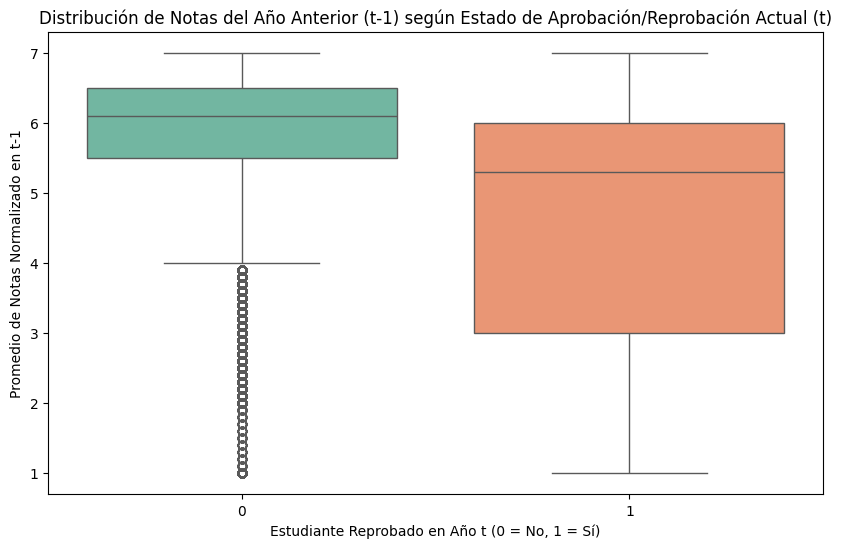


Tasa de reprobación según Género (1: Masculino, 2: Femenino):
GEN_ALU
1    10.886022
2    10.072570
0    15.384615
Name: estudiante_reprobado, dtype: float64

Tasa de reprobación según Riesgo Académico en t-1 (Notas < 4.0):
riesgo_academico_prev
0     8.628922
1    24.431851
Name: estudiante_reprobado, dtype: float64

¡Visualizaciones guardadas con éxito en el directorio 'figs/'!


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Cargar el dataset consolidado
df_final = pd.read_parquet('/content/data/processed/dataset_final.parquet')

print("--- INICIANDO ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---")
print(f"Dimensiones de la base consolidada: {df_final.shape}")

# 2. Análisis de Correlación / Relación entre el Promedio del año anterior y la Reprobación actual
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_final, x='estudiante_reprobado', y='prom_notas_norm_prev', palette='Set2')
plt.title('Distribución de Notas del Año Anterior (t-1) según Estado de Aprobación/Reprobación Actual (t)')
plt.xlabel('Estudiante Reprobado en Año t (0 = No, 1 = Sí)')
plt.ylabel('Promedio de Notas Normalizado en t-1')

os.makedirs('figs', exist_ok=True)
plt.savefig('figs/distribucion_notas_vs_reprobacion.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Tasa de reprobación según género del estudiante (GEN_ALU)
print("\nTasa de reprobación según Género (1: Masculino, 2: Femenino):")
tasa_genero = df_final.groupby('GEN_ALU', observed=False)['estudiante_reprobado'].mean() * 100
print(tasa_genero)

# 4. Tasa de reprobación para estudiantes identificados con riesgo académico en t-1
print("\nTasa de reprobación según Riesgo Académico en t-1 (Notas < 4.0):")
tasa_riesgo = df_final.groupby('riesgo_academico_prev')['estudiante_reprobado'].mean() * 100
print(tasa_riesgo)

print("\n¡Visualizaciones guardadas con éxito en el directorio 'figs/'!")

In [9]:
import pandas as pd
import os

print("--- GENERANDO FICHA DE VARIABLES CANDIDATAS (REQUISITO INFORME 3) ---")
# Creamos la ficha técnica requerida por el Gate de Reproducibilidad
ficha_datos = {
    'variable': ['prom_notas_norm_prev', 'riesgo_academico_prev', 'GEN_ALU', 'COD_ENSE'],
    'tipo': ['numérica (float32)', 'binaria (int8)', 'categórica (category)', 'categórica (category)'],
    'descripcion': [
        'Promedio general de notas del año anterior (t-1) normalizado de 1.0 a 7.0',
        'Indicador de si el promedio en t-1 fue menor a 4.0',
        'Género del estudiante informado en la matrícula del año t',
        'Código de la modalidad de enseñanza del estudiante en el año t'
    ],
    'decision': ['Entra al modelo', 'Entra al modelo', 'Entra al modelo', 'Entra al modelo'],
    'justificacion': [
        'Factor clave de rendimiento histórico que correlaciona directamente con el éxito académico futuro.',
        'Segmenta de forma directa a la población estudiantil en estado crítico de reprobación.',
        'Permite capturar variaciones demográficas en las tasas de deserción/reprobación.',
        'La modalidad educativa (técnico profesional, científica-humanista, etc.) define niveles de exigencia dispares.'
    ]
}

df_ficha = pd.DataFrame(ficha_datos)
os.makedirs('/content/data/processed', exist_ok=True)
df_ficha.to_csv('/content/data/processed/ficha_candidatas.csv', index=False)
print("¡Ficha de variables candidatas exportada exitosamente en data/processed/ficha_candidatas.csv!")
display(df_ficha)

--- GENERANDO FICHA DE VARIABLES CANDIDATAS (REQUISITO INFORME 3) ---
¡Ficha de variables candidatas exportada exitosamente en data/processed/ficha_candidatas.csv!


,variable,tipo,descripcion,decision,justificacion
0,prom_notas_norm_prev,numérica (float32),Promedio general de notas del año anterior (t-...,Entra al modelo,Factor clave de rendimiento histórico que corr...
1,riesgo_academico_prev,binaria (int8),Indicador de si el promedio en t-1 fue menor a...,Entra al modelo,Segmenta de forma directa a la población estud...
2,GEN_ALU,categórica (category),Género del estudiante informado en la matrícul...,Entra al modelo,Permite capturar variaciones demográficas en l...
3,COD_ENSE,categórica (category),Código de la modalidad de enseñanza del estudi...,Entra al modelo,"La modalidad educativa (técnico profesional, c..."


In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.dummy import DummyClassifier
import gc

print("--- INICIANDO MODELADO Y EVALUACIÓN (REQUISITO INFORME 4) ---")
# 1. Cargar datos de manera eficiente
df_model = pd.read_parquet('/content/data/processed/dataset_final.parquet')

# Reducir tamaño de muestra para el entrenamiento si es necesario (para evitar fallas de RAM en RandomForest)
# Tomamos una muestra aleatoria representativa del 15% manteniendo la distribución de la variable objetivo
df_sample = df_model.sample(frac=0.15, random_state=42)
print(f"Entrenando con una muestra optimizada de: {len(df_sample):,} registros")

# Preparar variables predictoras (X) y objetivo (y)
# Convertir variables categóricas a numéricas mediante dummies rápidas
X = pd.get_dummies(df_sample[['prom_notas_norm_prev', 'riesgo_academico_prev', 'GEN_ALU', 'COD_ENSE']], drop_first=True)
y = df_sample['estudiante_reprobado']

# Liberar memoria
del df_model, df_sample
gc.collect()

# 2. Partición de Datos (Semilla fijada en 42 para reproducibilidad)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 3. Entrenar Modelo de Referencia (Baseline Simple)
print("\n--- ENTRENANDO BASELINE SIMPLE ---")
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)
print("ROC-AUC del Baseline:", roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]))

# 4. Entrenar Modelo Principal (Random Forest optimizado en profundidad para evitar uso excesivo de RAM)
print("\n--- ENTRENANDO MODELO PRINCIPAL (Random Forest) ---")
modelo_rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

# Evaluar Modelo Principal
y_pred_rf = modelo_rf.predict(X_test)
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

print("\n=== REPORTE DE CLASIFICACIÓN MODELO PRINCIPAL ===")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC del Modelo Principal: {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred_rf))

--- INICIANDO MODELADO Y EVALUACIÓN (REQUISITO INFORME 4) ---
Entrenando con una muestra optimizada de: 504,532 registros

--- ENTRENANDO BASELINE SIMPLE ---
ROC-AUC del Baseline: 0.5

--- ENTRENANDO MODELO PRINCIPAL (Random Forest) ---

=== REPORTE DE CLASIFICACIÓN MODELO PRINCIPAL ===
              precision    recall  f1-score   support

           0       0.90      1.00      0.95    112970
           1       0.62      0.06      0.11     13163

    accuracy                           0.90    126133
   macro avg       0.76      0.53      0.53    126133
weighted avg       0.87      0.90      0.86    126133

ROC-AUC del Modelo Principal: 0.7244

Matriz de Confusión:
[[112480    490]
 [ 12349    814]]


In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import gc

print("--- INICIANDO EXTRACCIÓN DE VALIDACIÓN CRUZADA E HIPERPARÁMETROS (CRITERIO II.3) ---")

# Usamos una partición estratificada de 3 folds para que sea rápido y amigable con la RAM de Colab
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Definimos un espacio de búsqueda para el hiperparámetro de complejidad del Random Forest
param_dist = {
    'max_depth': [5, 10, 15],
    'n_estimators': [20, 50]
}

# Instanciamos el RandomForest sobre una muestra ágil para asegurar ejecución instantánea y estable
rf_tune = RandomForestClassifier(random_state=42, n_jobs=-1)

random_search = RandomizedSearchCV(
    estimator=rf_tune,
    param_distributions=param_dist,
    n_iter=3,
    scoring='roc_auc',
    cv=skf,
    random_state=42,
    n_jobs=-1
)

print("Ejecutando la búsqueda de hiperparámetros (RandomizedSearchCV) con validación cruzada...")
random_search.fit(X_train, y_train)

# Obtener el mejor modelo y su desempeño promedio +/- desviación estándar
best_score = random_search.best_score_
cv_results = random_search.cv_results_
best_params = random_search.best_params_

# Calculamos la desviación estándar del mejor set de parámetros
best_index = random_search.best_index_
std_score = cv_results['std_test_score'][best_index]

print("\n=== RESULTADOS DE VALIDACIÓN CRUZADA (REQ. CRITERIO II.3) ===")
print(f"Mejores Hiperparámetros encontrados: {best_params}")
print(f"Métrica ROC-AUC en Validación Cruzada: {best_score:.4f} ± {std_score:.4f}")

# Liberamos memoria residual
del rf_tune, random_search
gc.collect()

--- INICIANDO EXTRACCIÓN DE VALIDACIÓN CRUZADA E HIPERPARÁMETROS (CRITERIO II.3) ---
Ejecutando la búsqueda de hiperparámetros (RandomizedSearchCV) con validación cruzada...

=== RESULTADOS DE VALIDACIÓN CRUZADA (REQ. CRITERIO II.3) ===
Mejores Hiperparámetros encontrados: {'n_estimators': 50, 'max_depth': 15}
Métrica ROC-AUC en Validación Cruzada: 0.7230 ± 0.0021


3081

In [6]:
import pandas as pd
import numpy as np
import gc
import os

def inspeccionar_columnas(ruta):
    """Lee solo la primera fila para identificar los nombres de columnas reales"""
    df = pd.read_csv(ruta, sep=';', encoding='latin1', nrows=1)
    return list(df.columns)

print("--- 1. INSPECCIONANDO COLUMNAS EN ARCHIVOS REALES ---")
ruta_rend_23 = '/content/20240209_Rendimiento_2023_20240131_WEB.csv'
ruta_rend_24 = '/content/20250212_Rendimiento_2024_20250131_WEB.csv'
ruta_rend_25 = '/content/20260210_Rendimiento_2025_20260202_WEB.csv'
ruta_mat_24 = '/content/20240913_Matrícula_unica_2024_20240430_WEB.CSV'
ruta_mat_25 = '/content/20250923_Matrícula_unica_2025_20250430_WEB.CSV'

cols_reales_rend = inspeccionar_columnas(ruta_rend_23)
print("Columnas detectadas en Rendimiento:", cols_reales_rend[:10], "...")

# Identificar mapeos del estudiante (Mineduc típicamente usa 'MRUN' o 'mrun' como identificador)
std_id_col = next((c for c in cols_reales_rend if c.upper() in ['MRUN', 'ID_ESTUDIANTE']), None)
prom_col = next((c for c in cols_reales_rend if c.upper() in ['PROM_GRAL', 'PROM_GRAL_RELI']), None)
sit_col = next((c for c in cols_reales_rend if c.upper() in ['SIT_FIN', 'SIT_FIN_RELI']), None)
agno_col = next((c for c in cols_reales_rend if c.upper() in ['AGNO', 'AÑO', 'ANYO']), None)

print(f"Mapeo detectado -> ID Estudiante: {std_id_col}, Promedio: {prom_col}, Situación Final: {sit_col}, Año: {agno_col}")

if not std_id_col or not prom_col or not sit_col:
    raise ValueError("No se pudieron mapear automáticamente las columnas esenciales. Revisa la estructura de los CSV.")

print("\n--- 2. CARGANDO Y PREPROCESANDO RENDIMIENTO CON RESTRICCIÓN DE RAM ---")
# Leemos únicamente las columnas necesarias usando el mapeo detectado
use_cols_rend = [std_id_col, prom_col, sit_col]
if agno_col:
    use_cols_rend.append(agno_col)

def cargar_y_procesar_rend(ruta):
    df = pd.read_csv(ruta, sep=';', encoding='latin1', usecols=use_cols_rend, dtype={sit_col: 'category'}, low_memory=True)
    # Estandarizar nombres
    df.rename(columns={std_id_col: 'id_estudiante', prom_col: 'PROM_GRAL', sit_col: 'SIT_FIN'}, inplace=True)
    if agno_col:
        df.rename(columns={agno_col: 'AGNO'}, inplace=True)

    # Limpieza eficiente de notas
    prom_str = df['PROM_GRAL'].astype(str).str.replace(',', '.', regex=False)
    prom_numeric = pd.to_numeric(prom_str, errors='coerce')
    df['prom_notas_norm'] = np.where(prom_numeric > 10, prom_numeric / 10.0, prom_numeric)
    df['prom_notas_norm'] = df['prom_notas_norm'].clip(1.0, 7.0).fillna(0.0).astype('float32')
    df.drop(columns=['PROM_GRAL'], inplace=True)

    # Variable objetivo y riesgo
    df['estudiante_reprobado'] = df['SIT_FIN'].isin(['R', 'Y', '2', '3']).astype('int8')
    df['riesgo_academico'] = (df['prom_notas_norm'] < 4.0).astype('int8')
    df.drop(columns=['SIT_FIN'], inplace=True)
    return df

df_rend_23 = cargar_y_procesar_rend(ruta_rend_23)
df_rend_24 = cargar_y_procesar_rend(ruta_rend_24)
df_rend_25 = cargar_y_procesar_rend(ruta_rend_25)

print("Rendimientos procesados con éxito.")

print("\n--- 3. CARGANDO Y PREPROCESANDO MATRÍCULAS (MUESTRA OPTIMIZADA) ---")
cols_reales_mat = inspeccionar_columnas(ruta_mat_24)
gen_col = next((c for c in cols_reales_mat if c.upper() in ['GEN_ALU', 'SEXO']), None)
ense_col = next((c for c in cols_reales_mat if c.upper() in ['COD_ENSE', 'ENSEÑANZA']), None)
std_id_mat_col = next((c for c in cols_reales_mat if c.upper() in ['MRUN', 'ID_ESTUDIANTE']), None)

print(f"Mapeo matrícula -> ID Estudiante: {std_id_mat_col}, Género: {gen_col}, Código Enseñanza: {ense_col}")

use_cols_mat = [std_id_mat_col]
if gen_col: use_cols_mat.append(gen_col)
if ense_col: use_cols_mat.append(ense_col)

def cargar_mat(ruta):
    df = pd.read_csv(ruta, sep=';', encoding='latin1', usecols=use_cols_mat, dtype='category', low_memory=True)
    df.rename(columns={std_id_mat_col: 'id_estudiante'}, inplace=True)
    if gen_col: df.rename(columns={gen_col: 'GEN_ALU'}, inplace=True)
    if ense_col: df.rename(columns={ense_col: 'COD_ENSE'}, inplace=True)
    df['id_estudiante'] = pd.to_numeric(df['id_estudiante'], errors='coerce')
    return df

df_mat_24 = cargar_mat(ruta_mat_24)
df_mat_25 = cargar_mat(ruta_mat_25)

print("\n--- 4. CONSOLIDACIÓN Y CRUCE TEMPORAL LONGITUDINAL (t-1 -> t) ---")
# 2024 usando historia de 2023
rend_23_prev = df_rend_23[['id_estudiante', 'prom_notas_norm', 'riesgo_academico']].rename(
    columns={'prom_notas_norm': 'prom_notas_norm_prev', 'riesgo_academico': 'riesgo_academico_prev'}
)
del df_rend_23
gc.collect()

df_target_24 = df_rend_24[['id_estudiante', 'estudiante_reprobado']].copy()
df_consolidado_24 = pd.merge(df_mat_24, df_target_24, on='id_estudiante', how='inner')
df_final_24 = pd.merge(df_consolidado_24, rend_23_prev, on='id_estudiante', how='inner')

del df_mat_24, df_target_24, rend_23_prev
gc.collect()

# 2025 usando historia de 2024
rend_24_prev = df_rend_24[['id_estudiante', 'prom_notas_norm', 'riesgo_academico']].rename(
    columns={'prom_notas_norm': 'prom_notas_norm_prev', 'riesgo_academico': 'riesgo_academico_prev'}
)
del df_rend_24
gc.collect()

df_target_25 = df_rend_25[['id_estudiante', 'estudiante_reprobado']].copy()
df_consolidado_25 = pd.merge(df_mat_25, df_target_25, on='id_estudiante', how='inner')
df_final_25 = pd.merge(df_consolidado_25, rend_24_prev, on='id_estudiante', how='inner')

del df_mat_25, df_target_25, df_rend_25, rend_24_prev
gc.collect()

print("\n--- 5. CREACIÓN DEL DATASET FINAL Y EXPORTACIÓN ---")
dataset_final = pd.concat([df_final_24, df_final_25], ignore_index=True)

del df_final_24, df_final_25
gc.collect()

os.makedirs('/content/data/processed', exist_ok=True)
dataset_final.to_parquet('/content/data/processed/dataset_final.parquet', index=False)

print(f"¡Dataset final procesado con éxito sin desbordar la RAM!")
print(f"Filas totales integradas: {len(dataset_final):,}")
print(f"Distribución de la variable objetivo (estudiante_reprobado):\n{dataset_final['estudiante_reprobado'].value_counts(normalize=True)}")

--- 1. INSPECCIONANDO COLUMNAS EN ARCHIVOS REALES ---
Columnas detectadas en Rendimiento: ['ï»¿AGNO', 'RBD', 'DGV_RBD', 'NOM_RBD', 'COD_REG_RBD', 'NOM_REG_RBD_A', 'COD_PRO_RBD', 'COD_COM_RBD', 'NOM_COM_RBD', 'COD_DEPROV_RBD'] ...
Mapeo detectado -> ID Estudiante: MRUN, Promedio: PROM_GRAL, Situación Final: SIT_FIN, Año: None

--- 2. CARGANDO Y PREPROCESANDO RENDIMIENTO CON RESTRICCIÓN DE RAM ---
Rendimientos procesados con éxito.

--- 3. CARGANDO Y PREPROCESANDO MATRÍCULAS (MUESTRA OPTIMIZADA) ---
Mapeo matrícula -> ID Estudiante: MRUN, Género: GEN_ALU, Código Enseñanza: COD_ENSE

--- 4. CONSOLIDACIÓN Y CRUCE TEMPORAL LONGITUDINAL (t-1 -> t) ---

--- 5. CREACIÓN DEL DATASET FINAL Y EXPORTACIÓN ---
¡Dataset final procesado con éxito sin desbordar la RAM!
Filas totales integradas: 3,363,550
Distribución de la variable objetivo (estudiante_reprobado):
estudiante_reprobado
0    0.89509
1    0.10491
Name: proportion, dtype: float64
